In [3]:
from pydub import AudioSegment


In [4]:
audio = AudioSegment.from_file("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/song.mp3")


In [5]:
print("Duration (ms):", len(audio))
print("Channels:", audio.channels)
print("Frame Rate:", audio.frame_rate)
print("Sample Width (bytes):", audio.sample_width)
print("dBFS (average loudness):", audio.dBFS)

Duration (ms): 269026
Channels: 2
Frame Rate: 44100
Sample Width (bytes): 2
dBFS (average loudness): -17.416288623831296


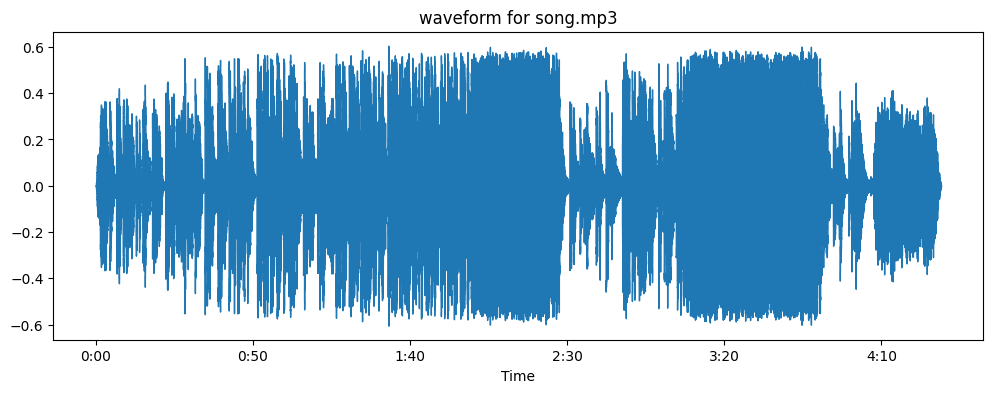

In [6]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

y, sr= librosa.load("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/song.mp3")

plt.figure(figsize=(12,4))
plt.title("waveform for song.mp3")
librosa.display.waveshow(y,sr=sr)
plt.show()

errors : ---------------------------------------------------------------------------
AttributeError                            Traceback (most recent call last)
Cell In[18], line 7
      3 import matplotlib.pyplot as plt
      5 y, sr= librosa.load("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/song.mp3")
----> 7 fade_in_audio = y[:5000].fade_in(3000)
      8 fade_out_audio = y[5000:10000].fade_out(3000)
     10 fade_in_clip = fade_in_audio.get_array_of_samples()

AttributeError: 'numpy.ndarray' object has no attribute 'fade_in'

to fix this :


Solution:
----------
* librosa -> load audio in Numpy array
* pydub -> is provide  "fade_in and fade_out" -> both are in methods of audio segment
* y[:5000].fade_in(3000) fails because y is just a NumPy array, not an audio clip.

ParameterError                            Traceback (most recent call last)
Cell In[19], line 25
     22 plt.figure(figsize=(12,4))
     24 plt.title("Fade In Audio")
---> 25 librosa.display.waveshow(fade_in_clip, sr=sr)
     26 plt.show()
     28 plt.figure(figsize=(12,4))

File ~/Documents/GitHub/YTmixtape/DJmix/lib/python3.9/site-packages/librosa/display.py:2027, in waveshow(y, sr, max_points, axis, offset, marker, where, label, transpose, ax, x_axis, **kwargs)
   1834 def waveshow(
   1835     y: np.ndarray,
   1836     *,
   (...)
   1847     **kwargs: Any,
   1848 ) -> AdaptiveWaveplot:
   1849     """Visualize a waveform in the time domain.
   1850 
   1851     This function constructs a plot which adaptively switches between a raw
   (...)
   2025     >>> ax['h'].set(title='transpose=True')
   2026     """
-> 2027     util.valid_audio(y)
   2029     # Pad an extra channel dimension, if necessary
   2030     if y.ndim == 1:
...
--> 287     raise ParameterError("Audio data must be of type numpy.ndarray")
    289 if not np.issubdtype(y.dtype, np.floating):
    290     raise ParameterError("Audio data must be floating-point")

ParameterError: Audio data must be of type numpy.ndarray


To fix this:
-----------
* we have to convert pydub inot Numpy arrry



Channels: 2
Sample Width (bytes): 2
Frame Rate:  44100
Channels: 2
Sample Width (bytes): 2
Frame Rate:  44100


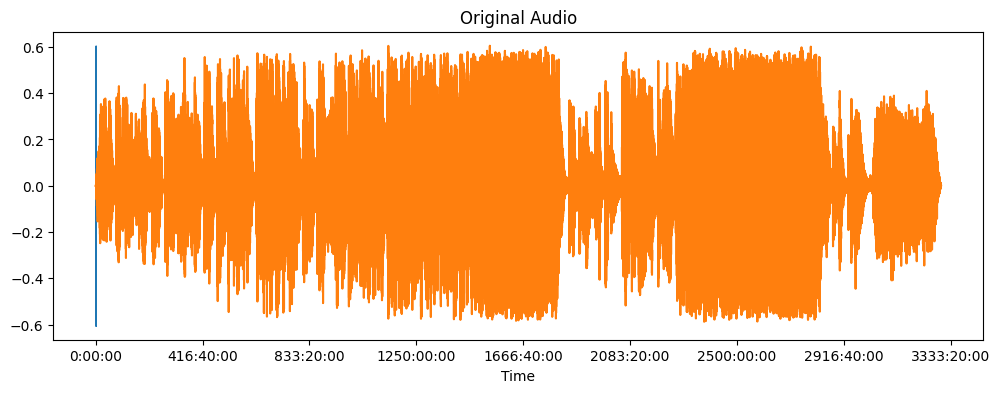

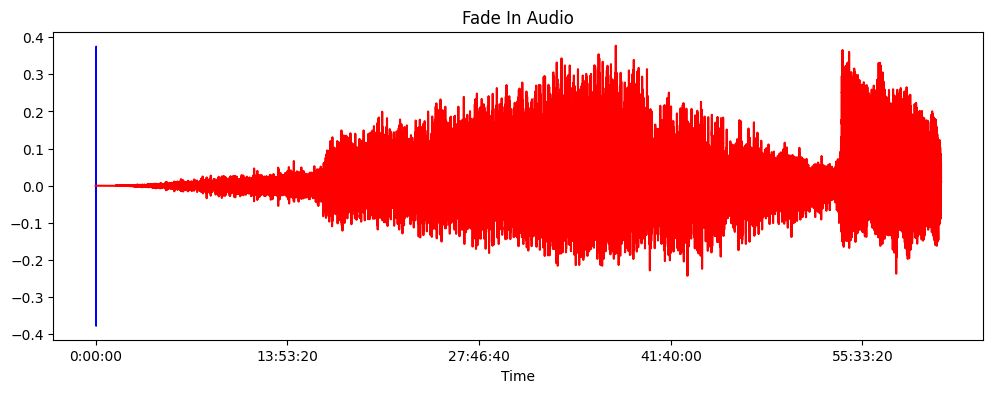

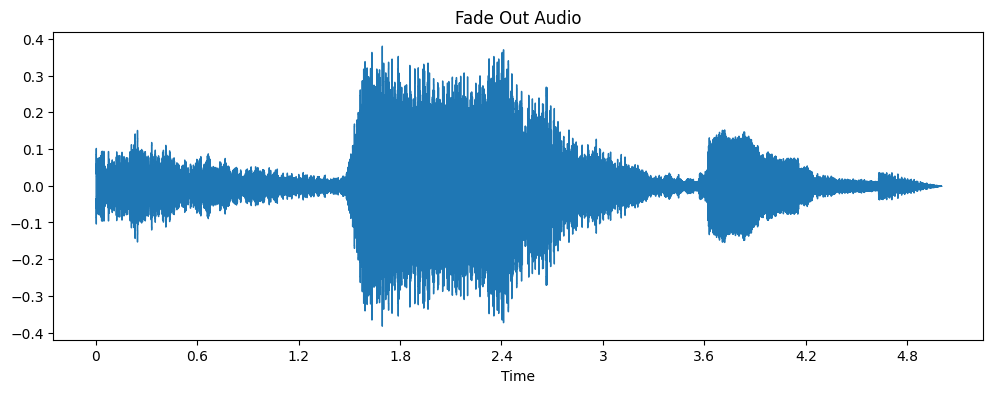

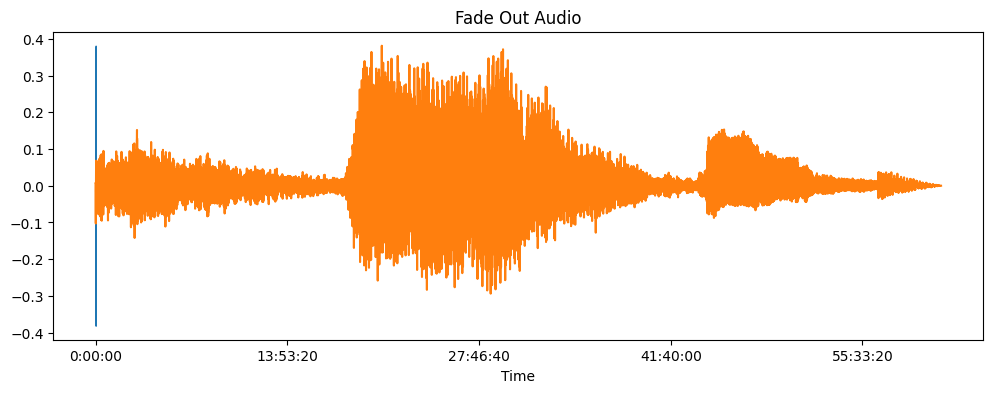

In [7]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
from pydub import AudioSegment
import numpy as np

audio = AudioSegment.from_file("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/song.mp3")
fade_in_audio = audio[:5000].fade_in(3000)
fade_out_audio = audio[5000:10000].fade_out(3000)

def audio_segment_to_numpy(audio_segment):
    samples = np.array(audio_segment.get_array_of_samples())

    print("Channels:", audio_segment.channels)
    print("Sample Width (bytes):", audio_segment.sample_width)
    print("Frame Rate: ", audio_segment.frame_rate)
    '''
        Channels: 2
        Frame Rate: 44100
        Sample Width (bytes): 2
        dBFS (average loudness): -17.416288623831296
    '''
    if audio_segment.channels == 2:
        samples = samples.reshape((-1,2))
        samples = samples.mean(axis=1)
    return samples.astype(np.float32) / (2 ** (audio_segment.sample_width * 8-1))

fade_in_clip = audio_segment_to_numpy(fade_in_audio)
fade_out_clip = audio_segment_to_numpy(fade_out_audio)

y, sr= librosa.load("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/song.mp3",sr=None)

plt.figure(figsize=(12,4))
librosa.display.waveshow(y, sr=sr)
plt.plot(y)
plt.title("Original Audio")
plt.show()

plt.figure(figsize=(12,4))
librosa.display.waveshow(fade_in_clip, sr=audio.frame_rate,color="blue")
plt.plot(fade_in_clip,color="red")
plt.title("Fade In Audio")
plt.show()




plt.figure(figsize=(12,4))
librosa.display.waveshow(fade_out_clip, sr=audio.frame_rate)
plt.title("Fade Out Audio")
plt.show()

plt.figure(figsize=(12,4))
librosa.display.waveshow(fade_out_clip, sr=audio.frame_rate)
plt.plot(fade_out_clip)
plt.title("Fade Out Audio")
plt.show()

In [4]:
import os
import random
from pydub import AudioSegment
def smooth_transition(folder, output, transition_ms=6000):
    try:
        files = [f for f in os.listdir("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/mixtape") if f.endswith((".mp3",".wav"))]
    except Exception as e:
        print(f"{e} : There is not track found in the folder.please try some another folder which containsth the songs.") # we hvae to aces teh songs in the file folder sio whe lopp throught 
                                                                            #them  by os module and that we stroe in varibale called f if hte song is mp3 or wav firl,
                                                                            # we stored all the things in the varibale clled file.
    # random.shuffle(files) # we have to shuufle the 'f'(one have all songs) in the file so we can get the random songs in the file.

# let we create varibel called mixtape and we will set it to none because we have to add the songs in the mixtape while in code.-> like a storage for the songs we will add in the mixtape.
    mixtape = None
    for i,file in enumerate(files):
        song = AudioSegment.from_file(os.path.join(folder,file))
        song = song.set_channels(2).set_frame_rate(44100)

        if mixtape is None: # if the first song is added to
            mixtape = song
        else:
            overlap = min(transition_ms, len(song), len(mixtape))
            outgoing = mixtape[-overlap:].fade_out(overlap).low_pass_filter(4000)
            incoming = song[:overlap].fade_in(overlap).low_pass_filter(4000)
            transition = outgoing.overlay(incoming)
            mixtape = mixtape[:-overlap] + transition + song[overlap:]

    print(output)
    print(os.path.exists(output))
    print(os.path.isdir(output))
    print(os.path.isfile(output))

    mixtape.export(output, format="mp3")
    print(f"✅ Smooth fade mixtape generated: {output}")


smooth_transition("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/mixtape","/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/ouput/final_mixtape.mp3")



/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/ouput/final_mixtape.mp3
False
False
False
✅ Smooth fade mixtape generated: /Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/ouput/final_mixtape.mp3


In [38]:
from pydub import AudioSegment
import os
def get_Discription(folder,mixtape_name,genre):
    try:
        files = [f for f in os.listdir(folder) if f.endswith((".mp3",".wav"))]
        print(files)
        print(f"✅ Found {len(files)} audio files in the folder: {folder}")
    except Exception as e:
        print(f"{e} : There is not track found in the folder.please try some another folder which containsth the songs.")

# Now the intro start as tracklist in Timestampes matching the songs transitions and the audio.
    
    current_time = 0
    transition_ms = 6000
    tracklist = []

    for file in files:
        minutes = int(current_time // 60)
        seconds = int(current_time % 60)

        tracklist.append(
            f"{minutes:02d}:{seconds:02d}{os.path.splitext(file)[0]}"

        )
        song = AudioSegment.from_file(os.path.join(folder, file))
        duration = len(song)/1000
        current_time += duration - (transition_ms/1000) # Convert milliseconds to seconds

    description = f"🔥 {mixtape_name} 🔥\n\n"
    description += f"🎵 Genre: {genre}\n\n"

    description += "🎵 Tracklist\n"
    description += "\n".join(tracklist)

    description += "\n\n💽 Download / Listen Links\n"
    description += "Find these tracks on Spotify, Apple Music or your favorite streaming platform.\n\n"

    description += "🎧 Follow for more Afro House DJ mixes!\n\n"

    hashtags = [
            "#AfroHouse", "#HouseMusic", "#EDM", "#DanceMusic", "#Mixtape",
            "#ElectronicMusic", "#DJMix", "#PartyMusic", "#DeepHouse", "#AfroHouseVibes"
        ]
    description += " ".join(hashtags)

    
    return description 

description_text = get_Discription(f"/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/mixtape","Afro House Summer Mix","Afro House")
print(f"Description: {description_text}")

with open("description.txt","w",encoding="utf-8") as file:
    file.write(description_text)




['Awen  Caiiro  Your Voice Adam Port Remix MIDH 043.mp3', 'Rgavan song .mp3', 'Waves  Wavs.mp3']
✅ Found 3 audio files in the folder: /Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/mixtape
Description: 🔥 Afro House Summer Mix 🔥

🎵 Genre: Afro House

🎵 Tracklist
00:00Awen  Caiiro  Your Voice Adam Port Remix MIDH 043
04:14Rgavan song 
08:37Waves  Wavs

💽 Download / Listen Links
Find these tracks on Spotify, Apple Music or your favorite streaming platform.

🎧 Follow for more Afro House DJ mixes!

#AfroHouse #HouseMusic #EDM #DanceMusic #Mixtape #ElectronicMusic #DJMix #PartyMusic #DeepHouse #AfroHouseVibes


In [9]:
import subprocess
import os
from PIL import Image

def video_geneartion(image, mixtape_audio, output_path="/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/ouput/mixtape_vid3.mp4",video_resolution=(1280,720), fps=1, preset="ultrafast"):
    if not os.path.exists(image):
        raise FileNotFoundError(f"Image not found: {image}")
    if not os.path.exists(mixtape_audio):
        raise FileNotFoundError(f"Audio not found: {mixtape_audio}")
    
    os.makedirs(os.path.dirname(output_path),exist_ok=True)

    rezising_image = "tem_image.jpg"
    img = Image.open(image)
    img = img.resize(video_resolution)
    img.save(rezising_image)
    print(f"✅Image rezised : {rezising_image}")


    cmd = [
        "ffmpeg",              # invoke FFmpeg program
        "-y",                  # overwrite output file without asking
        "-loop", "1",          # loop the input image (so it stays on screen)
        "-i", rezising_image,  # input #1: the static image
        "-i", mixtape_audio,        # input #2: the audio track (mp3/wav/etc.)
        "-c:v", "libx264",       # encode video using H.264 codec
        "-preset", preset,       # encoding speed/quality preset (e.g. 'fast', 'medium')
        "-tune", "stillimage",   # optimize encoding for a static image
        "-r", str(fps),          # set frames per second (low = smaller file)
        "-c:a", "aac",           # encode audio using AAC codec
        "-b:a", "192k",          # set audio bitrate to 192kbps
        "-shortest",             # stop encoding when the shortest input ends (audio ends)
        output_path              # output file path (e.g. .mp4)
    ]

    try:
        subprocess.run(cmd,check=True)
        print(f"✅ Video created: {output_path}")   
    except subprocess.CalledProcessError as e:
        print("❌ FFmpeg failed! Error:", e)
    finally:
        # Clean up temporary resized image
        if os.path.exists(rezising_image):
            os.remove(rezising_image)
        
video_geneartion("/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/images/hh.png","/Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/ouput/final_mixtape.mp3")  

✅Image rezised : tem_image.jpg


ffmpeg version 8.1.2 Copyright (c) 2000-2026 the FFmpeg developers
  built with Apple clang version 21.0.0 (clang-2100.0.123.102)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.1.2_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags= --enable-ffplay --enable-gpl --enable-libsvtav1 --enable-libopus --enable-libx264 --enable-libmp3lame --enable-libdav1d --enable-libvmaf --enable-libvpx --enable-libx265 --enable-openssl --enable-videotoolbox --enable-audiotoolbox --enable-neon
  libavutil      60. 26.102 / 60. 26.102
  libavcodec     62. 28.102 / 62. 28.102
  libavformat    62. 12.102 / 62. 12.102
  libavdevice    62.  3.102 / 62.  3.102
  libavfilter    11. 14.102 / 11. 14.102
  libswscale      9.  5.102 /  9.  5.102
  libswresample   6.  3.102 /  6.  3.102
Input #0, image2, from 'tem_image.jpg':
  Duration: 00:00:00.04, start: 0.000000, bitrate: 22709 kb/s
  Stream #0:0: Video: mjpeg (Baseline), yuvj420p(pc, bt470bg/unknown/unknown), 1

✅ Video created: /Users/ragava/Documents/GitHub/YTmixtape/experiment_notebooks/ouput/mixtape_vid3.mp4


[out#0/mp4 @ 0xa38c243c0] video:2953KiB audio:20243KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.668400%
frame=  859 fps= 17 q=-1.0 Lsize=   23351KiB time=00:14:05.72 bitrate= 226.2kbits/s dup=0 drop=20792 speed=  17x elapsed=0:00:49.80    
[libx264 @ 0xa38c21180] frame I:4     Avg QP: 5.00  size:442523
[libx264 @ 0xa38c21180] frame P:855   Avg QP: 1.23  size:  1466
[libx264 @ 0xa38c21180] mb I  I16..4: 100.0%  0.0%  0.0%
[libx264 @ 0xa38c21180] mb P  I16..4:  0.0%  0.0%  0.0%  P16..4:  5.1%  0.0%  0.0%  0.0%  0.0%    skip:94.8%
[libx264 @ 0xa38c21180] coded y,uvDC,uvAC intra: 87.9% 79.8% 67.7% inter: 1.8% 0.7% 0.7%
[libx264 @ 0xa38c21180] i16 v,h,dc,p: 31% 21% 22% 27%
[libx264 @ 0xa38c21180] i8c dc,h,v,p: 41% 22% 24% 13%
[libx264 @ 0xa38c21180] kb/s:28.16
[aac @ 0xa38c21c00] Qavg: 542.876
